## 1 · Imports & Setup

In [1]:
import os, json, glob, tempfile, shutil, datetime
import numpy as np
import pandas as pd
from pathlib import Path
from PIL import Image
from collections import Counter

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision.models as models
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader
from torch.cuda.amp import GradScaler, autocast

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, f1_score, precision_score, recall_score
from tqdm import tqdm
import matplotlib.pyplot as plt

os.environ["PYTORCH_ALLOC_CONF"] = "expandable_segments:True"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = True
scaler = GradScaler()
print(f"Device: {device}")


Device: cuda


/tmp/ipykernel_58/3037662903.py:25: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()


## 2 · Config

In [2]:
# ── Paths ──────────────────────────────────────────────────────────────────
base           = "/kaggle/input/datasets"
import kagglehub
# Phase D (pre-F2) checkpoints — pull Version 1 specifically. Only needed if
# you're re-running F2 training from scratch (Sections 11–15). Later versions
# (2/3/4) contain F2-era uploads, including the corrupted "Final F2 upload".
phase_ckpt_dir = kagglehub.dataset_download("vitthaljauhari2/cropquerydataset/versions/1")
print("Path to dataset files:", phase_ckpt_dir)
f2_runs_dir    = "/kaggle/working/runs_f2"
os.makedirs(f2_runs_dir, exist_ok=True)

# Final, already-trained F2 checkpoints — attached to this notebook as an
# input at a fixed path (whichever dataset version is currently attached in
# the Kaggle UI; no version number in the path itself). This is what
# inference (Sections 17, 18, 22) actually loads — training never has to run.
latest_ckpt_dir = os.path.join(base, "vitthaljauhari2", "cropquerydataset")

# ── Data ───────────────────────────────────────────────────────────────────
img_size      = 224
batch_size    = 64
f2_batch_size = 32       # halved — F2 does 2 forward passes per batch
num_workers   = 4
seed          = 42
image_exts    = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# ── F2 training ────────────────────────────────────────────────────────────
LAMBDA_CONSISTENCY     = 0.10
f2_n_epochs            = 10
f2_early_stop_patience = 3

# ── Layer-wise LRs ─────────────────────────────────────────────────────────
lr_head   = 5e-4
lr_top    = 5e-5
lr_mid    = 2e-5
lr_bottom = 1e-5

# ── F2 checkpoint paths ──────────────────────────────────────────────────
# Points at the final trained model in the attached dataset by default, so
# every inference cell below just works without training. If you DO want to
# re-run F2 training (Section 14), it writes to f2_runs_dir — repoint this
# dict at f2_runs_dir once that finishes if you want to eval a fresh run
# instead of the dataset's checkpoints.
F2_CKPTS = {
    "resnet50":     f"{latest_ckpt_dir}/resnet50_f2_best.pth",
    "efficientnet": f"{latest_ckpt_dir}/efficientnet_f2_best.pth",
    "densenet":     f"{latest_ckpt_dir}/densenet_f2_best.pth",
}

# ── FAISS bank output ──────────────────────────────────────────────────────
# The attached dataset also ships a pre-built feature bank
# (feature_bank_features.npy / feature_bank_labels.npy) — if you want FAISS
# eval without re-running Section 16, point OUT_FEATURES/OUT_LABELS at
# latest_ckpt_dir instead of these local paths before running Section 16b.
OUT_FEATURES     = "/kaggle/working/feature_bank_features.npy"
OUT_LABELS       = "/kaggle/working/feature_bank_labels.npy"
OUT_FEATURES_BAL = "/kaggle/working/feature_bank_features_balanced.npy"
OUT_LABELS_BAL   = "/kaggle/working/feature_bank_labels_balanced.npy"


Path to dataset files: /kaggle/input/datasets/vitthaljauhari2/cropquerydataset


## 3 · Transforms

In [3]:
mean = [0.485, 0.456, 0.406]
std  = [0.229, 0.224, 0.225]

val_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(img_size),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

# Weak / strong augmentation pair for F2 consistency loss.
# Both branches are applied independently, so they differ in geometry too.
aug_weak = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.RandomResizedCrop(img_size, scale=(0.6, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(30),
    transforms.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.3, hue=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

aug_strong = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.RandomResizedCrop(img_size, scale=(0.6, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(30),
    transforms.ColorJitter(brightness=0.8, contrast=0.8, saturation=0.8, hue=0.2),
    transforms.RandomGrayscale(p=0.2),
    transforms.GaussianBlur(kernel_size=5, sigma=(0.1, 2.0)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])


## 4 · Dataset Classes

In [4]:
class CropDiseaseDataset(Dataset):
    """Single-view dataset — used for validation / eval."""
    def __init__(self, samples, transform=None):
        self.samples   = samples
        self.transform = transform
    def __len__(self):
        return len(self.samples)
    def __getitem__(self, idx):
        path, label = self.samples[idx]
        img = Image.open(path).convert("RGB")
        if self.transform:
            img = self.transform(img)
        return img, label


class ConsistencyDataset(Dataset):
    """Returns two augmented views (weak + strong) of the same image for F2 loss."""
    def __init__(self, samples, aug_a, aug_b):
        self.samples = samples
        self.aug_a   = aug_a
        self.aug_b   = aug_b
    def __len__(self):
        return len(self.samples)
    def __getitem__(self, idx):
        path, label = self.samples[idx]
        img = Image.open(path).convert("RGB")
        return self.aug_a(img), self.aug_b(img), label


## 5 · Label Maps

In [5]:
dataset_label_maps = {
    # tushar5harma: 3-level structure  Crop/Split/Disease
    "tushar5harma": {
        ("Apple",        "Apple Scab"):             "Apple__Apple_Scab",
        ("Apple",        "Black Rot"):              "Apple__Black_Rot",
        ("Apple",        "Cedar Apple Rust"):       "Apple__Cedar_Apple_Rust",
        ("Apple",        "Healthy"):                "Apple__Healthy",
        ("Bell Pepper",  "Bacterial Spot"):         "Bell_Pepper__Bacterial_Spot",
        ("Bell Pepper",  "Healthy"):                "Bell_Pepper__Healthy",
        ("Cherry",       "Healthy"):                "Cherry__Healthy",
        ("Cherry",       "Powdery Mildew"):         "Cherry__Powdery_Mildew",
        ("Corn (Maize)", "Cercospora Leaf Spot"):   "Corn__Gray_Leaf_Spot",
        ("Corn (Maize)", "Common Rust"):            "Corn__Common_Rust",
        ("Corn (Maize)", "Healthy"):                "Corn__Healthy",
        ("Corn (Maize)", "Northern Leaf Blight"):   "Corn__Northern_Leaf_Blight",
        ("Grape",        "Black Rot"):              "Grape__Black_Rot",
        ("Grape",        "Esca (Black Measles)"):   "Grape__Black_Measles",
        ("Grape",        "Healthy"):                "Grape__Healthy",
        ("Grape",        "Leaf Blight"):            "Grape__Leaf_Blight",
        ("Peach",        "Bacterial Spot"):         "Peach__Bacterial_Spot",
        ("Peach",        "Healthy"):                "Peach__Healthy",
        ("Potato",       "Early Blight"):           "Potato__Early_Blight",
        ("Potato",       "Healthy"):                "Potato__Healthy",
        ("Potato",       "Late Blight"):            "Potato__Late_Blight",
        ("Strawberry",   "Healthy"):                "Strawberry__Healthy",
        ("Strawberry",   "Leaf Scorch"):            "Strawberry__Leaf_Scorch",
        ("Tomato",       "Bacterial Spot"):         "Tomato__Bacterial_Spot",
        ("Tomato",       "Early Blight"):           "Tomato__Early_Blight",
        ("Tomato",       "Healthy"):                "Tomato__Healthy",
        ("Tomato",       "Late Blight"):            "Tomato__Late_Blight",
        ("Tomato",       "Septoria Leaf Spot"):     "Tomato__Septoria_Leaf_Spot",
        ("Tomato",       "Yellow Leaf Curl Virus"): "Tomato__Yellow_Leaf_Curl_Virus",
    },
    "shubham2703": {
        "Corn___Common_Rust":          "Corn__Common_Rust",
        "Corn___Gray_Leaf_Spot":       "Corn__Gray_Leaf_Spot",
        "Corn___Healthy":              "Corn__Healthy",
        "Corn___Northern_Leaf_Blight": "Corn__Northern_Leaf_Blight",
        "Potato___Early_Blight":       "Potato__Early_Blight",
        "Potato___Healthy":            "Potato__Healthy",
        "Potato___Late_Blight":        "Potato__Late_Blight",
        "Rice___Brown_Spot":           "Rice__Brown_Spot",
        "Rice___Healthy":              "Rice__Healthy",
        "Rice___Leaf_Blast":           "Rice__Leaf_Blast",
        "Rice___Neck_Blast":           "Rice__Neck_Blast",
        "Wheat___Brown_Rust":          "Wheat__Brown_Rust",
        "Wheat___Healthy":             "Wheat__Healthy",
        "Wheat___Yellow_Rust":         "Wheat__Yellow_Rust",
        "Bacterial Blight":            "Rice__Bacterial_Blight",
        "Red Rot":                     "Sugarcane__Red_Rot",
    },
    "nirmalsankalana": {
        "coffee___healthy":         "Coffee__Healthy",
        "coffee___red_spider_mite": "Coffee__Red_Spider_Mite",
        "coffee___rust":            "Coffee__Rust",
        "BlackMeasles":             "Grape__Black_Measles",
        "BlackRot":                 "Grape__Black_Rot",
        "HealthyGrapes":            "Grape__Healthy",
        "LeafBlight":               "Grape__Leaf_Blight",
    },
    "binnassor89": {
        "calcium":  "Melon__Calcium_Deficiency",
        "health":   "Melon__Healthy",
        "nitrogen": "Melon__Nitrogen_Deficiency",
        "potasium": "Melon__Potassium_Deficiency",   # sic — matches disk
    },
    "zunorain": {
        "DOWNY_MILDEW_LEAF":  "Pea__Downy_Mildew",
        "FRESH_LEAF":         "Pea__Healthy",
        "LEAFMINNER_LEAF":    "Pea__Leaf_Miner",
        "POWDER_MILDEW_LEAF": "Pea__Powdery_Mildew",
    },
    "ayushbpanchal": {
        "anthracnose": "Cashew__Anthracnose",
        "gumosis":     "Cashew__Gummosis",
        "healthy":     "Cashew__Healthy",
        "leaf miner":  "Cashew__Leaf_Miner",
        "red rust":    "Cashew__Red_Rust",
    },
    "tahmidmir": {
        "Bacterial Leaf Spot": "Pumpkin__Bacterial_Leaf_Spot",
        "Downy Mildew":        "Pumpkin__Downy_Mildew",
        "Healthy Leaf":        "Pumpkin__Healthy",
        "Mosaic Disease":      "Pumpkin__Mosaic_Disease",
        "Powdery_Mildew":      "Pumpkin__Powdery_Mildew",
    },
    "mexwell": {
        "Cassava Bacterial Blight (CBB)":      "Cassava__Bacterial_Blight",
        "Cassava Brown Streak Disease (CBSD)": "Cassava__Brown_Streak_Disease",
        "Cassava Green Mottle (CGM)":          "Cassava__Green_Mottle",
        "Cassava Mosaic Disease (CMD)":        "Cassava__Mosaic_Disease",
        "Healthy":                             "Cassava__Healthy",
    },
    "yasaminborhani": {
        "Brown_rust":  "Wheat__Brown_Rust",
        "Healthy":     "Wheat__Healthy",
        "Yellow_rust": "Wheat__Yellow_Rust",
    },
}

all_canonical = sorted(set(v for lm in dataset_label_maps.values() for v in lm.values()))
class_to_idx  = {c: i for i, c in enumerate(all_canonical)}
idx_to_class  = {i: c for c, i in class_to_idx.items()}
n_classes     = len(class_to_idx)
backbone_names = ["resnet50", "efficientnet", "densenet"]
print(f"Classes: {n_classes}")

Classes: 64


## 6 · Sample Builders

In [6]:
def build_samples_folder(slug):
    label_map = dataset_label_maps[slug]
    root = Path(base) / slug
    samples, skipped = [], 0
    for img_path in root.rglob("*"):
        if img_path.suffix.lower() not in image_exts:
            continue
        raw_label = img_path.parent.name
        canonical = None
        # Special-case: bare "Healthy" folder in shubham2703 needs crop prefix
        if slug == "shubham2703" and raw_label == "Healthy":
            crop_folder = img_path.parent.parent.name
            if crop_folder in ["Corn", "Potato", "Rice", "Wheat", "Sugarcane"]:
                canonical = f"{crop_folder}__Healthy"
                if canonical not in class_to_idx:
                    canonical = None
        if canonical is None:
            canonical = label_map.get(raw_label)
        if canonical is None:
            skipped += 1
            continue
        samples.append((str(img_path), class_to_idx[canonical]))
    print(f"  [{slug:<20}] {len(samples):>6} samples  ({skipped} skipped)")
    return samples


def build_samples_tushar():
    label_map = dataset_label_maps["tushar5harma"]
    root = Path(base) / "tushar5harma"
    samples, skipped = [], 0
    for img_path in root.rglob("*"):
        if img_path.suffix.lower() not in image_exts:
            continue
        disease_dir = img_path.parent
        split_dir   = disease_dir.parent
        crop_dir    = split_dir.parent
        if disease_dir.name.startswith(".") or split_dir.name.startswith("."):
            skipped += 1
            continue
        canonical = label_map.get((crop_dir.name, disease_dir.name.strip()))
        if canonical is None:
            skipped += 1
            continue
        samples.append((str(img_path), class_to_idx[canonical]))
    print(f"  [{'tushar5harma':<20}] {len(samples):>6} samples  ({skipped} skipped)")
    return samples


def build_samples_mexwell():
    data_root = Path(base) / "mexwell" / "crop-diseases-classification" / "Data"
    with open(data_root / "label_num_to_disease_map.json") as f:
        num_to_name = json.load(f)
    df = pd.read_csv(data_root / "train.csv")
    label_map = dataset_label_maps["mexwell"]
    img_dir = data_root / "train_images"
    samples, skipped = [], 0
    for _, row in df.iterrows():
        img_path  = img_dir / row["image_id"]
        if not img_path.exists():
            skipped += 1
            continue
        canonical = label_map.get(num_to_name[str(row["label"])])
        if canonical is None:
            skipped += 1
            continue
        samples.append((str(img_path), class_to_idx[canonical]))
    print(f"  [{'mexwell':<20}] {len(samples):>6} samples  ({skipped} skipped)")
    return samples


def build_all_samples():
    print("Loading datasets...")
    folder_slugs = ["shubham2703", "nirmalsankalana", "binnassor89",
                    "zunorain", "ayushbpanchal", "tahmidmir", "yasaminborhani"]
    samples = []
    for slug in folder_slugs:
        samples += build_samples_folder(slug)
    samples += build_samples_mexwell()
    samples += build_samples_tushar()
    print(f"\nTotal: {len(samples):,} | {len(set(l for _, l in samples))} classes")
    return samples

## 7 · Build Samples + Split + DataLoaders

In [7]:
all_samples = build_all_samples()
labels_all  = [lbl for _, lbl in all_samples]

train_s, val_s = train_test_split(
    all_samples, test_size=0.15, random_state=seed, stratify=labels_all
)
print(f"Train: {len(train_s):,} | Val: {len(val_s):,}")

f2_train_ds = ConsistencyDataset(train_s, aug_weak, aug_strong)
f2_val_ds   = CropDiseaseDataset(val_s, transform=val_transform)

kw = dict(num_workers=num_workers, prefetch_factor=4,
          persistent_workers=True, pin_memory=True)

f2_train_loader = DataLoader(f2_train_ds, batch_size=f2_batch_size, shuffle=True,  **kw)
f2_val_loader   = DataLoader(f2_val_ds,   batch_size=f2_batch_size, shuffle=False, **kw)
print(f"Train batches: {len(f2_train_loader)} | Val batches: {len(f2_val_loader)}")


Loading datasets...
  [shubham2703         ]  13224 samples  (100 skipped)
  [nirmalsankalana     ]   1560 samples  (0 skipped)
  [binnassor89         ]    200 samples  (0 skipped)
  [zunorain            ]   1432 samples  (0 skipped)
  [ayushbpanchal       ]  25811 samples  (0 skipped)
  [tahmidmir           ]   2000 samples  (0 skipped)
  [yasaminborhani      ]   3679 samples  (0 skipped)
  [mexwell             ]  17938 samples  (3459 skipped)
  [tushar5harma        ]  67111 samples  (7 skipped)

Total: 132,955 | 64 classes
Train: 113,011 | Val: 19,944
Train batches: 3532 | Val batches: 624


## 8 · Backbone Classes

In [8]:
class ResNet50Backbone(nn.Module):
    feature_dim = 2048
    def __init__(self, n_classes, dropout=0.4):
        super().__init__()
        backbone_net = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
        self.encoder = nn.Sequential(*list(backbone_net.children())[:-1])
        self.head    = nn.Sequential(nn.Dropout(dropout), nn.Linear(2048, n_classes))
    def extract_features(self, x):
        return self.encoder(x).flatten(1)
    def forward(self, x):
        return self.head(self.extract_features(x))


class EfficientNetB3Backbone(nn.Module):
    feature_dim = 1536
    def __init__(self, n_classes, dropout=0.4):
        super().__init__()
        backbone_net = models.efficientnet_b3(weights=models.EfficientNet_B3_Weights.IMAGENET1K_V1)
        self.encoder = backbone_net.features
        self.pool    = backbone_net.avgpool
        self.head    = nn.Sequential(nn.Dropout(dropout), nn.Linear(1536, n_classes))
    def extract_features(self, x):
        return self.pool(self.encoder(x)).flatten(1)
    def forward(self, x):
        return self.head(self.extract_features(x))


class DenseNet121Backbone(nn.Module):
    feature_dim = 1024
    def __init__(self, n_classes, dropout=0.4):
        super().__init__()
        backbone_net = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)
        self.encoder = backbone_net.features
        self.pool    = nn.AdaptiveAvgPool2d(1)
        self.head    = nn.Sequential(nn.Dropout(dropout), nn.Linear(1024, n_classes))
    def extract_features(self, x):
        return self.pool(F.relu(self.encoder(x))).flatten(1)
    def forward(self, x):
        return self.head(self.extract_features(x))


BACKBONE_CLASSES = {
    "resnet50":     ResNet50Backbone,
    "efficientnet": EfficientNetB3Backbone,
    "densenet":     DenseNet121Backbone,
}

def build_all_backbones(n_classes):
    bb = {name: cls(n_classes).to(device) for name, cls in BACKBONE_CLASSES.items()}
    for name, m in bb.items():
        print(f"  {name:<15} {sum(p.numel() for p in m.parameters())/1e6:.1f}M params")
    return bb


## 9 · Optimizers

In [9]:
def build_optimizer_resnet(model):
    enc = list(model.encoder.children())
    return optim.AdamW([
        {"params": list(enc[0].parameters()) + list(enc[1].parameters()), "lr": lr_bottom},
        {"params": enc[4].parameters(), "lr": lr_bottom},
        {"params": enc[5].parameters(), "lr": lr_mid},
        {"params": enc[6].parameters(), "lr": lr_top},
        {"params": enc[7].parameters(), "lr": lr_top},
        {"params": model.head.parameters(),  "lr": lr_head},
    ], weight_decay=1e-4)

def build_optimizer_effnet_densenet(model):
    enc = list(model.encoder.children())
    mid = len(enc) // 2
    return optim.AdamW([
        {"params": enc[0].parameters(), "lr": lr_bottom},
        {"params": sum([list(enc[i].parameters()) for i in range(1, mid)],   []), "lr": lr_mid},
        {"params": sum([list(enc[i].parameters()) for i in range(mid, len(enc))], []), "lr": lr_top},
        {"params": model.head.parameters(), "lr": lr_head},
    ], weight_decay=1e-4)

def build_optimizers(backbones):
    return {
        "resnet50":     build_optimizer_resnet(backbones["resnet50"]),
        "efficientnet": build_optimizer_effnet_densenet(backbones["efficientnet"]),
        "densenet":     build_optimizer_effnet_densenet(backbones["densenet"]),
    }

## 10 · Training Utilities

In [10]:
class AverageMeter:
    def __init__(self): self.reset()
    def reset(self): self.sum = self.count = self.avg = 0
    def update(self, val, n=1):
        self.sum += val * n; self.count += n; self.avg = self.sum / self.count


def accuracy_topk(output, target, topk=(1, 5)):
    with torch.no_grad():
        maxk = max(topk)
        bs   = target.size(0)
        _, pred = output.topk(maxk, dim=1, largest=True, sorted=True)
        correct = pred.t().eq(target.view(1, -1).expand_as(pred.t()))
        return [correct[:k].reshape(-1).float().sum().mul_(100.0 / bs).item() for k in topk]


@torch.no_grad()
def evaluate(name, model, loader):
    model.eval()
    t1 = t5 = total = 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        a1, a5 = accuracy_topk(model(imgs), labels)
        t1 += a1 * labels.size(0); t5 += a5 * labels.size(0); total += labels.size(0)
    top1, top5 = t1 / total, t5 / total
    print(f"  [{name}] Val top1={top1:.2f}%  top5={top5:.2f}%")
    return top1, top5


@torch.no_grad()
def ensemble_predict_loader(backbones_dict, loader):
    """Ensemble prediction using backbones ALREADY IN MEMORY (e.g. mid-training
    snapshots). For post-hoc eval from saved checkpoint files, use
    `run_backbones_over_loader` below instead."""
    for m in backbones_dict.values(): m.eval()
    all_preds, all_labels = [], []
    for imgs, labels in loader:
        imgs  = imgs.to(device)
        probs = sum(F.softmax(m(imgs), dim=1) for m in backbones_dict.values()) / len(backbones_dict)
        all_preds.extend(probs.argmax(dim=1).cpu().numpy())
        all_labels.extend(labels.numpy())
    return np.array(all_preds), np.array(all_labels)


def load_backbone_checkpoint(name, ckpt_path, n_classes, device, model=None):
    """Instantiate (unless `model` is given) a backbone and load a checkpoint's
    weights onto it. Returns (model, checkpoint_dict) — the dict still carries
    epoch/best_acc/etc. for logging."""
    if model is None:
        model = BACKBONE_CLASSES[name](n_classes).to(device)
    ckpt = torch.load(ckpt_path, map_location="cpu")
    model.load_state_dict(ckpt["model_state_dict"])
    return model, ckpt


@torch.no_grad()
def run_backbones_over_loader(ckpt_dict, loader, mode="probs", desc_prefix=""):
    """Load each backbone fresh from its checkpoint, run it over `loader`, then
    free GPU memory before moving to the next backbone.

    mode="probs"    -> dict name -> softmax probs,           shape (N, n_classes)
    mode="features" -> dict name -> penultimate-layer features, shape (N, feature_dim)

    This is the shared routine behind: FAISS feature-bank rebuild, ensemble
    test-split eval, and FAISS query-feature extraction — those three used to
    each have their own near-identical load/inference loop.
    """
    results = {}
    for name, ckpt_path in ckpt_dict.items():
        print(f"\n── {name} ──")
        model, ckpt = load_backbone_checkpoint(name, ckpt_path, n_classes, device)
        print(f"  epoch={ckpt['epoch']} | best_acc={ckpt['best_acc']:.4f}")
        model.eval()
        out = []
        for imgs, _ in tqdm(loader, desc=f"{desc_prefix}{name}"):
            imgs = imgs.to(device)
            if mode == "probs":
                out.append(torch.softmax(model(imgs), dim=1).cpu().numpy())
            elif mode == "features":
                out.append(model.extract_features(imgs).cpu().numpy())
            else:
                raise ValueError(f"Unknown mode: {mode!r}")
        results[name] = np.concatenate(out)
        model.cpu(); del model
        torch.cuda.empty_cache(); torch.cuda.synchronize()
    return results


def ensemble_average(probs_dict):
    """Simple unweighted average of per-backbone softmax probs."""
    names = list(probs_dict.keys())
    return sum(probs_dict[n] for n in names) / len(names)


def concat_features_in_order(feat_dict, order=("resnet50", "efficientnet", "densenet")):
    """Concatenate per-backbone features along dim=1 in a FIXED order. The
    FAISS bank and any query features must use the same order to stay comparable."""
    return np.concatenate([feat_dict[name] for name in order], axis=1).astype(np.float32)


def macro_weighted_f1(labels, preds):
    return (f1_score(labels, preds, average="macro"),
            f1_score(labels, preds, average="weighted"))


## 11 · Load Phase D Checkpoints + Baseline Eval

Version 1 predates the F2 naming convention (`_best.pth`, not `_f2_best.pth`). `load_backbone_checkpoint` below will raise immediately if any of the three fails to load cleanly — we don't want to build 10 epochs on top of a silently corrupted baseline.

In [ ]:
backbones = build_all_backbones(n_classes)

for name in backbone_names:
    ckpt_path = os.path.join(phase_ckpt_dir, f"{name}_best.pth")  # Phase D naming — no _f2_ suffix
    _, ckpt = load_backbone_checkpoint(name, ckpt_path, n_classes, device, model=backbones[name])
    print(f"  Loaded {name} | epoch={ckpt['epoch']} | best_acc={ckpt['best_acc']:.4f}")

optimizers = build_optimizers(backbones)

# Baseline snapshot — MUST run before F2 training overwrites weights in-place
preds_before, labels_before = ensemble_predict_loader(backbones, f2_val_loader)
report_before = classification_report(
    labels_before, preds_before,
    target_names=[idx_to_class[i] for i in range(n_classes)],
    output_dict=True, zero_division=0,
)
print(f"Pre-F2 ensemble  macro F1={report_before['macro avg']['f1-score']:.4f}"
      f"  weighted F1={report_before['weighted avg']['f1-score']:.4f}")


## 12 · Atomic Checkpoint Saving

In [ ]:
# ── Atomic checkpoint saving ────────────────────────────────────────────────
# torch.save() writes the ZIP central directory only at the very end of the
# call. If the kernel is OOM-killed mid-write, the file on disk has valid
# local headers but no central directory — "failed finding central
# directory" on load, and it is NOT recoverable. This happened to our F2
# checkpoints (June 2026): all 6 files (best + latest, all 3 backbones)
# were corrupted this way.
#
# Fix: write to a temp file in the same directory, then os.replace() onto
# the final path. os.replace() is atomic on POSIX, so a crash mid-write
# leaves the temp file corrupted (harmless, discarded) and the previous
# good checkpoint at the final path untouched.
import tempfile

def atomic_torch_save(obj, final_path):
    dir_ = os.path.dirname(final_path)
    fd, tmp_path = tempfile.mkstemp(dir=dir_, suffix=".pth.tmp")
    os.close(fd)
    try:
        torch.save(obj, tmp_path)
        os.replace(tmp_path, final_path)
    except Exception:
        if os.path.exists(tmp_path):
            os.remove(tmp_path)
        raise

print("atomic_torch_save() ready — all F2 checkpoint saves below use this.")


## 13 · F2 Training Functions

In [ ]:
def train_one_epoch_f2(name, model, loader, criterion, optimizer, epoch):
    model.train()
    loss_m = AverageMeter(); ce_m = AverageMeter()
    kl_m   = AverageMeter(); top1_m = AverageMeter()
    loop = tqdm(loader, desc=f"{name} F2-E{epoch}")

    for imgs_a, imgs_b, labels in loop:
        imgs_a, imgs_b, labels = imgs_a.to(device), imgs_b.to(device), labels.to(device)
        optimizer.zero_grad()
        with autocast():
            out_a  = model(imgs_a)
            out_b  = model(imgs_b)
            ce     = criterion(out_a, labels)
            kl     = F.kl_div(
                F.log_softmax(out_a, dim=1),
                F.softmax(out_b.detach(), dim=1),   # stop-grad on strong branch
                reduction="batchmean",
            )
            loss = ce + LAMBDA_CONSISTENCY * kl
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer); scaler.update()

        top1, _ = accuracy_topk(out_a, labels)
        bs = imgs_a.size(0)
        loss_m.update(loss.item(), bs); ce_m.update(ce.item(), bs)
        kl_m.update(kl.item(), bs);    top1_m.update(top1, bs)
        loop.set_postfix(loss=loss_m.avg, ce=ce_m.avg, kl=kl_m.avg, accuracy=top1_m.avg)

    return loss_m.avg, ce_m.avg, kl_m.avg, top1_m.avg


def train_backbone_f2(name, model, train_loader, val_loader, optimizer):
    resume_path = os.path.join(f2_runs_dir, f"{name}_f2_latest.pth")
    scheduler   = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=f2_n_epochs, eta_min=1e-7)
    criterion   = nn.CrossEntropyLoss(label_smoothing=0.1)
    start_epoch = 0; best_top1 = 0.0; no_improve = 0; history = []

    if os.path.exists(resume_path):
        try:
            print(f"Resuming {name} from {resume_path}")
            ckpt = torch.load(resume_path, map_location="cpu")
            model.load_state_dict(ckpt["model_state_dict"])
            optimizer.load_state_dict(ckpt["optimizer_state_dict"])
            scheduler.load_state_dict(ckpt["scheduler_state_dict"])
            start_epoch = ckpt["epoch"] + 1
            best_top1   = ckpt.get("best_acc", 0.0)
            history     = ckpt.get("history", [])
            print(f"  Resumed at epoch {start_epoch}, best_top1={best_top1:.4f}")
        except Exception as e:
            # Corrupted/truncated resume file (e.g. from an earlier OOM kill).
            # Don't silently train on top of a half-loaded model — start this
            # backbone fresh from the Phase D weights already in `model`.
            print(f"  WARNING: resume checkpoint at {resume_path} failed to load ({e})")
            print(f"  Starting {name} fresh from Phase D weights instead of resuming.")
            start_epoch = 0; best_top1 = 0.0; no_improve = 0; history = []

    print(f"\n{'='*60}\nF2: {name}  epochs {start_epoch}..{f2_n_epochs-1}  λ={LAMBDA_CONSISTENCY}\n{'='*60}")

    for epoch in range(start_epoch, f2_n_epochs):
        tr_loss, tr_ce, tr_kl, tr1 = train_one_epoch_f2(name, model, train_loader, criterion, optimizer, epoch)
        val_top1, val_top5 = evaluate(name, model, val_loader)
        scheduler.step()
        history.append(dict(epoch=epoch, tr_loss=tr_loss, tr_ce=tr_ce, tr_kl=tr_kl,
                            tr_top1=tr1, val_top1=val_top1))
        print(f"  Epoch {epoch}: train={tr1:.2f}%  val={val_top1:.2f}%  ce={tr_ce:.4f}  kl={tr_kl:.4f}")

        base_ckpt = dict(
            backbone=name, epoch=epoch, model_state_dict=model.state_dict(),
            optimizer_state_dict=optimizer.state_dict(),
            scheduler_state_dict=scheduler.state_dict(),
            best_acc=val_top1, class_to_idx=class_to_idx, n_classes=n_classes, history=history,
        )
        atomic_torch_save(base_ckpt, os.path.join(f2_runs_dir, f"{name}_f2_latest.pth"))

        if val_top1 > best_top1:
            best_top1  = val_top1
            no_improve = 0
            atomic_torch_save(base_ckpt, os.path.join(f2_runs_dir, f"{name}_f2_best.pth"))
            print(f"  -> {name}_f2_best.pth  (top1={best_top1:.4f})")
        else:
            no_improve += 1
            print(f"  No improvement ({no_improve}/{f2_early_stop_patience})")
            if no_improve >= f2_early_stop_patience:
                print(f"  Early stopping at epoch {epoch}")
                break

    print(f"\n{name} done. Best val top1: {best_top1:.4f}")
    return os.path.join(f2_runs_dir, f"{name}_f2_best.pth")

## 14 · Clear Stale F2 Checkpoints, Then Run F2 Training

We're resuming from the verified Phase D baseline, not from any previous F2 run. First remove leftover `_f2_latest.pth` / `_f2_best.pth` files in `f2_runs_dir` so `train_backbone_f2` can't accidentally auto-resume from an old (possibly corrupted) F2 checkpoint — then run training.

In [ ]:
stale = glob.glob(os.path.join(f2_runs_dir, "*_f2_*.pth"))
if stale:
    print(f"Removing {len(stale)} stale F2 checkpoint(s):")
    for p in stale:
        print(" ", p)
        os.remove(p)
else:
    print("No stale F2 checkpoints found — clean start.")


In [ ]:
f2_best_paths = {}

for name in backbone_names:
    print(f"\n{'#'*60}\n# Starting {name}\n{'#'*60}")
    f2_best_paths[name] = train_backbone_f2(
        name, backbones[name], f2_train_loader, f2_val_loader, optimizers[name]
    )
    backbones[name].cpu()
    del optimizers[name]
    torch.cuda.empty_cache(); torch.cuda.synchronize()
    print(f"  GPU freed — {torch.cuda.memory_allocated()/1e9:.2f} GB allocated")

    # ── Mid-run backup ──────────────────────────────────────────────────
    # Zip runs_f2/ after every backbone finishes and copy to a stable
    # location, so a crash on the NEXT backbone can't cost you a backbone
    # you've already completed. Download this zip periodically too.
    backup_stamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
    backup_path  = f"/kaggle/working/f2_runs_backup_{name}_{backup_stamp}"
    shutil.make_archive(backup_path, "zip", f2_runs_dir)
    print(f"  Backed up runs_f2/ -> {backup_path}.zip")

print("\nBest checkpoints:")
for name, path in f2_best_paths.items():
    print(f"  {name}: {path}")


## 15 · Per-class F1 Delta (Before → After F2)

In [ ]:
for m in backbones.values(): m.to(device); m.eval()

preds_after, labels_after = ensemble_predict_loader(backbones, f2_val_loader)
report_after = classification_report(
    labels_after, preds_after,
    target_names=[idx_to_class[i] for i in range(n_classes)],
    output_dict=True, zero_division=0,
)

weak_classes = sorted(c for c in idx_to_class.values()
                      if "cassava" in c.lower() or "cashew" in c.lower())

print("=== F2 Per-class F1 — Cassava + Cashew (before -> after) ===")
for c in weak_classes:
    b = report_before.get(c, {}).get("f1-score")
    a = report_after.get(c, {}).get("f1-score")
    if b is not None and a is not None:
        d = a - b
        print(f"  {c:<35} {b:.4f} -> {a:.4f}   ({'+' if d>=0 else ''}{d:.4f})")

print(f"\nMacro F1:    before={report_before['macro avg']['f1-score']:.4f}  "
      f"after={report_after['macro avg']['f1-score']:.4f}")
print(f"Weighted F1: before={report_before['weighted avg']['f1-score']:.4f}  "
      f"after={report_after['weighted avg']['f1-score']:.4f}")


## 16 · FAISS Feature Bank Rebuild

Run once after F2 training. Rebuilds the `.npy` bank from F2 checkpoint features.
Expected output: `(113011, 4608)`.

In [ ]:
train_bank_ds = CropDiseaseDataset(train_s, transform=val_transform)
bank_loader   = DataLoader(
    train_bank_ds, batch_size=128, shuffle=False,
    num_workers=num_workers, pin_memory=True,
    prefetch_factor=4, persistent_workers=True,
)
print(f"Bank train split: {len(train_bank_ds):,} samples  (expected ~113,011)")

bank_feat_dict = run_backbones_over_loader(F2_CKPTS, bank_loader, mode="features")
bank_features  = concat_features_in_order(bank_feat_dict)
labels_bank    = np.array([lbl for _, lbl in train_s])  # loader is shuffle=False -> order matches train_s

assert bank_features.shape == (len(train_s), 4608), f"Shape mismatch: {bank_features.shape}"

np.save(OUT_FEATURES, bank_features)
np.save(OUT_LABELS,   labels_bank)

unique, counts = np.unique(labels_bank, return_counts=True)
print(f"\nSaved: {bank_features.shape}  →  {OUT_FEATURES}")
print(f"Classes covered: {len(unique)}/64  |  "
      f"min {counts.min()} ({idx_to_class[unique[counts.argmin()]]})  "
      f"max {counts.max()} ({idx_to_class[unique[counts.argmax()]]})")


## 16b · Class-Balanced FAISS Bank

Caps over-represented classes (e.g. Cassava Mosaic at 9,373 samples) so k-NN voting isn't dominated by one class.

In [ ]:
# Reload from disk (via the Config constants, not hardcoded paths) — lets this
# section run independently without re-running feature extraction above.
bank_features = np.load(OUT_FEATURES)
labels_bank   = np.load(OUT_LABELS)


In [ ]:
# ── Class-Balanced FAISS Bank (rebuild from already-extracted features) ───
MAX_PER_CLASS = 800   # cap dominant classes; tune if needed

rng = np.random.default_rng(seed)
keep_idx = []
for cls in np.unique(labels_bank):
    cls_idx = np.where(labels_bank == cls)[0]
    if len(cls_idx) > MAX_PER_CLASS:
        cls_idx = rng.choice(cls_idx, size=MAX_PER_CLASS, replace=False)
    keep_idx.append(cls_idx)
keep_idx = np.concatenate(keep_idx)
rng.shuffle(keep_idx)

balanced_features = bank_features[keep_idx]
balanced_labels   = labels_bank[keep_idx]

OUT_FEATURES_BAL = "/kaggle/working/feature_bank_features_balanced.npy"
OUT_LABELS_BAL   = "/kaggle/working/feature_bank_labels_balanced.npy"
np.save(OUT_FEATURES_BAL, balanced_features)
np.save(OUT_LABELS_BAL,   balanced_labels)

unique, counts = np.unique(balanced_labels, return_counts=True)
print(f"Balanced bank: {balanced_features.shape}  (was {bank_features.shape})")
print(f"Classes covered: {len(unique)}/64  |  "
      f"min {counts.min()} ({idx_to_class[unique[counts.argmin()]]})  "
      f"max {counts.max()} ({idx_to_class[unique[counts.argmax()]]})")


## 17 · Ensemble Test-Split Eval

In [12]:
test_ds     = CropDiseaseDataset(val_s, transform=val_transform)
test_loader = DataLoader(test_ds, batch_size=128, shuffle=False, num_workers=num_workers, pin_memory=True)
gt_labels   = np.array([lbl for _, lbl in val_s])
print(f"Test split: {len(val_s):,} samples  (expected ~19,944)")

all_probs = run_backbones_over_loader(F2_CKPTS, test_loader, mode="probs")
for name, probs in all_probs.items():
    preds_s = probs.argmax(axis=1)
    print(f"  {name} Top-1: {(preds_s == gt_labels).mean()*100:.4f}%")

ensemble_probs = ensemble_average(all_probs)
ensemble_preds = ensemble_probs.argmax(axis=1)

top1 = (ensemble_preds == gt_labels).mean() * 100
top5 = sum(gt_labels[i] in ensemble_probs[i].argsort()[-5:] for i in range(len(gt_labels))) / len(gt_labels) * 100
macro_f1, weighted_f1 = macro_weighted_f1(gt_labels, ensemble_preds)

print("\n" + "="*55)
print("  ENSEMBLE F2 — TEST SPLIT RESULTS")
print("="*55)
print(f"  Top-1       : {top1:.4f}%   (Phase D baseline: 96.92%)")
print(f"  Top-5       : {top5:.4f}%")
print(f"  Macro F1    : {macro_f1:.4f}   (Phase D baseline: 0.9425)")
print(f"  Weighted F1 : {weighted_f1:.4f}   (Phase D baseline: 0.9618)")
print("="*55)

# Cassava per-class F1
print("\nCassava cluster F1:")
per_class_f1 = f1_score(gt_labels, ensemble_preds, average=None)
for cls in sorted(c for c in class_to_idx if c.startswith("Cassava")):
    print(f"  {cls:<40} {per_class_f1[class_to_idx[cls]]:.4f}")

# Top-10 error pairs
print("\nTop-10 confused pairs:")
errors = Counter((idx_to_class[g], idx_to_class[p]) for g, p in zip(gt_labels, ensemble_preds) if g != p)
for (gt_cls, pred_cls), cnt in errors.most_common(10):
    print(f"  {gt_cls} → {pred_cls:<45} {cnt}")


Test split: 19,944 samples  (expected ~19,944)

── resnet50 ──
  epoch=9 | best_acc=96.6857


resnet50: 100%|██████████| 156/156 [01:21<00:00,  1.91it/s]



── efficientnet ──
Downloading: "https://download.pytorch.org/models/efficientnet_b3_rwightman-b3899882.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b3_rwightman-b3899882.pth


100%|██████████| 47.2M/47.2M [00:00<00:00, 188MB/s]


  epoch=8 | best_acc=95.6629


...


── densenet ──
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 178MB/s]


  epoch=9 | best_acc=96.6606


densenet: 100%|██████████| 156/156 [01:19<00:00,  1.97it/s]


  resnet50 Top-1: 96.6857%
  efficientnet Top-1: 95.6629%
  densenet Top-1: 96.6606%

  ENSEMBLE F2 — TEST SPLIT RESULTS
  Top-1       : 97.2423%   (Phase D baseline: 96.92%)
  Top-5       : 99.9749%
  Macro F1    : 0.9493   (Phase D baseline: 0.9425)
  Weighted F1 : 0.9722   (Phase D baseline: 0.9618)

Cassava cluster F1:
  Cassava__Bacterial_Blight                0.6931
  Cassava__Brown_Streak_Disease            0.7771
  Cassava__Green_Mottle                    0.7927
  Cassava__Healthy                         0.7186
  Cassava__Mosaic_Disease                  0.9546

Top-10 confused pairs:
  Cassava__Brown_Streak_Disease → Cassava__Healthy                              37
  Cassava__Mosaic_Disease → Cassava__Green_Mottle                         33
  Cassava__Green_Mottle → Cassava__Mosaic_Disease                       32
  Cassava__Healthy → Cassava__Bacterial_Blight                     27
  Cassava__Healthy → Cassava__Mosaic_Disease                       27
  Cassava__Bacterial_Bligh

## 18 · Ensemble + FAISS Eval — Balanced Bank + Weighted Voting

In [14]:
! pip install faiss-cpu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.5/18.5 MB 73.3 MB/s eta 0:00:00:00:0100:01


In [15]:
import faiss

CONFIDENCE_GATE = 80.0
FAISS_MIN_SIM   = 0.65
K               = 7

# Step 1: Build FAISS index from the BALANCED bank
print("Loading balanced feature bank...")
bank_feats  = np.load(OUT_FEATURES_BAL).astype(np.float32)
bank_labels = np.load(OUT_LABELS_BAL)
faiss.normalize_L2(bank_feats)
index = faiss.IndexFlatIP(bank_feats.shape[1])
index.add(bank_feats)
print(f"Index: {index.ntotal} vectors  dim={bank_feats.shape[1]}")

# Step 2: Extract 4608-dim features for test split (one backbone at a time)
test_feat_dict = run_backbones_over_loader(F2_CKPTS, test_loader, mode="features")
test_features  = concat_features_in_order(test_feat_dict)
assert test_features.shape == (len(val_s), 4608), f"Shape mismatch: {test_features.shape}"
print(f"\nTest features: {test_features.shape}")

# Step 3: Batch FAISS query
faiss.normalize_L2(test_features)
distances, indices = index.search(test_features, K)

# Step 4: Similarity-weighted vote (replaces plain majority vote — majority
# vote let many mediocre neighbours outvote one genuinely close match)
faiss_preds = np.zeros(len(test_features), dtype=np.int64)
for i in range(len(test_features)):
    votes = np.zeros(n_classes, dtype=np.float64)
    for j in range(K):
        votes[bank_labels[indices[i, j]]] += distances[i, j]
    faiss_preds[i] = votes.argmax()
faiss_sims = distances[:, 0]

# Step 5: Apply gate — override ensemble when low-confidence AND sim >= floor
ensemble_conf   = ensemble_probs.max(axis=1) * 100.0
faiss_triggered = (ensemble_conf < CONFIDENCE_GATE) & (faiss_sims >= FAISS_MIN_SIM)

final_preds = ensemble_preds.copy()
final_preds[faiss_triggered] = faiss_preds[faiss_triggered]

# Step 6: Metrics
top1_f           = (final_preds == gt_labels).mean() * 100
macro_f1, wt_f1   = macro_weighted_f1(gt_labels, final_preds)
n_trig            = faiss_triggered.sum()
n_correct         = (final_preds[faiss_triggered] == gt_labels[faiss_triggered]).sum()

print("\n" + "="*60)
print("  ENSEMBLE + BALANCED-FAISS (weighted vote) — TEST SPLIT")
print("="*60)
print(f"  Top-1 (F2 only)     : {(ensemble_preds==gt_labels).mean()*100:.4f}%")
print(f"  Top-1 (F2 + FAISS)  : {top1_f:.4f}%")
print(f"  Macro F1            : {macro_f1:.4f}")
print(f"  Weighted F1         : {wt_f1:.4f}")
print(f"  FAISS triggered     : {n_trig}/{len(test_features)} ({n_trig/len(test_features)*100:.2f}%)")
print(f"  Override accuracy   : {n_correct}/{n_trig} ({n_correct/n_trig*100:.1f}% correct when triggered)")
print("="*60)


Loading balanced feature bank...
Index: 41089 vectors  dim=4608

── resnet50 ──
  epoch=9 | best_acc=96.6857


resnet50: 100%|██████████| 156/156 [01:04<00:00,  2.42it/s]



── efficientnet ──
  epoch=8 | best_acc=95.6629


efficientnet: 100%|██████████| 156/156 [00:56<00:00,  2.76it/s]



── densenet ──
  epoch=9 | best_acc=96.6606


densenet: 100%|██████████| 156/156 [01:00<00:00,  2.59it/s]



Test features: (19944, 4608)

  ENSEMBLE + BALANCED-FAISS (weighted vote) — TEST SPLIT
  Top-1 (F2 only)     : 97.2423%
  Top-1 (F2 + FAISS)  : 96.9164%
  Macro F1            : 0.9452
  Weighted F1         : 0.9694
  FAISS triggered     : 2504/19944 (12.56%)
  Override accuracy   : 1967/2504 (78.6% correct when triggered)


## 19 · τ × min_sim Sweep

In [16]:
# ── τ × min_sim sweep — balanced bank, weighted vote ──────────────────────
baseline_top1 = (ensemble_preds == gt_labels).mean() * 100

print(f"  {'τ':>5}  {'sim':>5}  {'Top-1':>9}  {'Triggered':>10}  {'Ov.acc':>8}")
print("  " + "-"*52)
best_acc, best_tau, best_sim = 0, 0, 0
for tau in [65, 70, 75, 80, 85, 90]:
    for min_sim in [0.60, 0.65, 0.70, 0.75, 0.80, 0.85, 0.90]:
        trig  = (ensemble_conf < tau) & (faiss_sims >= min_sim)
        preds = ensemble_preds.copy()
        if trig.sum() > 0:
            preds[trig] = faiss_preds[trig]
        acc    = (preds == gt_labels).mean() * 100
        ov_acc = (preds[trig] == gt_labels[trig]).mean() * 100 if trig.sum() > 0 else 0
        marker = ""
        if acc > best_acc:
            best_acc, best_tau, best_sim = acc, tau, min_sim
            marker = " ◄ BEST"
        print(f"  τ={tau:>2}%  s={min_sim:.2f}  {acc:>9.4f}%  {trig.sum():>10}  {ov_acc:>7.1f}%{marker}")
    print()

print(f"Best: τ={best_tau}%  min_sim={best_sim:.2f}  Top-1={best_acc:.4f}%")
print(f"F2-only baseline: {baseline_top1:.4f}%")
print(f"Delta vs F2-only: {best_acc - baseline_top1:+.4f}pp")


      τ    sim      Top-1   Triggered    Ov.acc
  ----------------------------------------------------
  τ=65%  s=0.60    96.9615%        1202     67.8% ◄ BEST
  τ=65%  s=0.65    96.9615%        1202     67.8%
  τ=65%  s=0.70    96.9615%        1201     67.8%
  τ=65%  s=0.75    96.9665%        1187     68.0% ◄ BEST
  τ=65%  s=0.80    96.9765%        1155     68.5% ◄ BEST
  τ=65%  s=0.85    97.0417%        1037     70.9% ◄ BEST
  τ=65%  s=0.90    97.1871%         672     78.1% ◄ BEST

  τ=70%  s=0.60    96.9414%        1494     70.4%
  τ=70%  s=0.65    96.9414%        1494     70.4%
  τ=70%  s=0.70    96.9414%        1493     70.4%
  τ=70%  s=0.75    96.9465%        1479     70.6%
  τ=70%  s=0.80    96.9565%        1447     71.0%
  τ=70%  s=0.85    97.0267%        1307     73.2%
  τ=70%  s=0.90    97.1671%         871     79.0%

  τ=75%  s=0.60    96.9214%        1868     73.7%
  τ=75%  s=0.65    96.9214%        1868     73.7%
  τ=75%  s=0.70    96.9214%        1867     73.6%
  τ=75%  s

## 20 · Backbone & Ensemble Ablation Plot

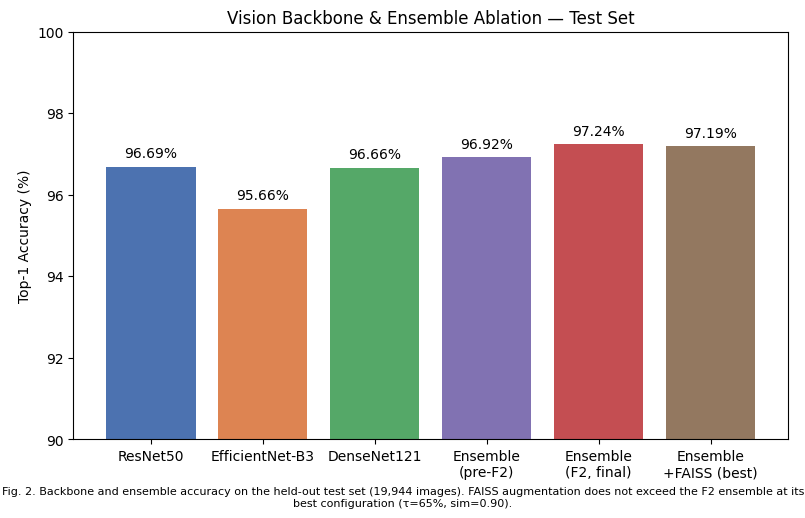

In [17]:
labels = ["ResNet50", "EfficientNet-B3", "DenseNet121", "Ensemble\n(pre-F2)", "Ensemble\n(F2, final)", "Ensemble\n+FAISS (best)"]
accuracies = [96.6857, 95.6629, 96.6606, 96.92, 97.2423, 97.1871]
colors = ["#4C72B0", "#DD8452", "#55A868", "#8172B2", "#C44E52", "#937860"]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(labels, accuracies, color=colors)

for bar, acc in zip(bars, accuracies):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.15,
            f"{acc:.2f}%", ha="center", va="bottom", fontsize=10)

ax.set_ylabel("Top-1 Accuracy (%)")
ax.set_ylim(90, 100)
ax.set_title("Vision Backbone & Ensemble Ablation — Test Set")
plt.figtext(0.5, -0.02,
            "Fig. 2. Backbone and ensemble accuracy on the held-out test set (19,944 images). "
            "FAISS augmentation does not exceed the F2 ensemble at its best configuration (τ=65%, sim=0.90).",
            wrap=True, ha="center", fontsize=8)

plt.tight_layout()
plt.savefig("fig2_ablation.png", dpi=300, bbox_inches="tight")
plt.show()

## 21 · Class Count

In [13]:
all_samples = build_all_samples()

# Count samples by integer class label
class_counts = Counter(lbl for _, lbl in all_samples)

# Build table with actual canonical class names
rows = []

for class_idx in range(n_classes):
    rows.append({
        "Class ID": class_idx,
        "Class Name": idx_to_class[class_idx],
        "Image Count": class_counts.get(class_idx, 0)
    })

df_counts = pd.DataFrame(rows)

# Lowest number of images first — useful for deciding what to scrape
df_counts = df_counts.sort_values(
    "Image Count", ascending=True
).reset_index(drop=True)

display(df_counts)

print(f"Total classes: {len(df_counts)}")
print(f"Total images: {df_counts['Image Count'].sum():,}")
print(f"Min per class: {df_counts['Image Count'].min():,}")
print(f"Max per class: {df_counts['Image Count'].max():,}")
print(f"Mean per class: {df_counts['Image Count'].mean():.1f}")
print(f"Median per class: {df_counts['Image Count'].median():.1f}")


Loading datasets...
  [shubham2703         ]  13224 samples  (100 skipped)
  [nirmalsankalana     ]   1560 samples  (0 skipped)
  [binnassor89         ]    200 samples  (0 skipped)
  [zunorain            ]   1432 samples  (0 skipped)
  [ayushbpanchal       ]  25811 samples  (0 skipped)
  [tahmidmir           ]   2000 samples  (0 skipped)
  [yasaminborhani      ]   3679 samples  (0 skipped)
  [mexwell             ]  17938 samples  (3459 skipped)
  [tushar5harma        ]  67111 samples  (7 skipped)

Total: 132,955 | 64 classes


,Class ID,Class Name,Image Count
0,29,Melon__Calcium_Deficiency,50
1,30,Melon__Healthy,50
2,31,Melon__Nitrogen_Deficiency,50
3,32,Melon__Potassium_Deficiency,50
4,47,Rice__Bacterial_Blight,100
...,...,...,...
59,6,Cashew__Anthracnose,4940
60,9,Cashew__Leaf_Miner,4953
61,10,Cashew__Red_Rust,6566
62,8,Cashew__Healthy,7213


Total classes: 64
Total images: 132,955
Min per class: 50
Max per class: 11,027
Mean per class: 2077.4
Median per class: 2156.0


In [19]:
df_counts.to_csv("sample_counts.csv", index=False, header=True)


## 22 · Per-Class F1

In [14]:
# Per-class F1 (+ precision/recall) for the ensemble on the test split.
# Reuses gt_labels / ensemble_preds from Section 17 — run that first.
per_class_precision = precision_score(gt_labels, ensemble_preds, average=None, labels=range(n_classes), zero_division=0)
per_class_recall    = recall_score(gt_labels, ensemble_preds, average=None, labels=range(n_classes), zero_division=0)
per_class_f1_full   = f1_score(gt_labels, ensemble_preds, average=None, labels=range(n_classes), zero_division=0)

rows = []
for class_idx in range(n_classes):
    rows.append({
        "Class ID": class_idx,
        "Class Name": idx_to_class[class_idx],
        "Support": int((gt_labels == class_idx).sum()),
        "Precision": per_class_precision[class_idx],
        "Recall": per_class_recall[class_idx],
        "F1": per_class_f1_full[class_idx],
    })

df_f1 = pd.DataFrame(rows)

# Worst-performing classes first — useful for deciding what to fix/scrape
df_f1 = df_f1.sort_values("F1", ascending=True).reset_index(drop=True)

display(df_f1)

print(f"Macro F1:    {per_class_f1_full.mean():.4f}")
print(f"Weighted F1: {f1_score(gt_labels, ensemble_preds, average='weighted'):.4f}")
print(f"Worst class: {df_f1.iloc[0]['Class Name']} (F1={df_f1.iloc[0]['F1']:.4f})")
print(f"Best class:  {df_f1.iloc[-1]['Class Name']} (F1={df_f1.iloc[-1]['F1']:.4f})")

df_f1.to_csv("per_class_f1.csv", index=False, header=True)


,Class ID,Class Name,Support,Precision,Recall,F1
0,19,Coffee__Red_Spider_Mite,25,0.500000,0.360000,0.418605
1,11,Cassava__Bacterial_Blight,138,0.690647,0.695652,0.693141
2,14,Cassava__Healthy,325,0.699708,0.738462,0.718563
3,12,Cassava__Brown_Streak_Disease,275,0.849138,0.716364,0.777120
4,46,Pumpkin__Powdery_Mildew,60,0.860000,0.716667,0.781818
...,...,...,...,...,...,...
59,39,Potato__Early_Blight,514,1.000000,1.000000,1.000000
60,54,Sugarcane__Red_Rot,15,1.000000,1.000000,1.000000
61,53,Strawberry__Leaf_Scorch,333,1.000000,1.000000,1.000000
62,52,Strawberry__Healthy,342,1.000000,1.000000,1.000000


Macro F1:    0.9493
Weighted F1: 0.9722
Worst class: Coffee__Red_Spider_Mite (F1=0.4186)
Best class:  Rice__Neck_Blast (F1=1.0000)


In [15]:
class_counts_df = pd.merge(df_counts, df_f1, on=["Class ID", "Class Name"])
class_counts_df

,Class ID,Class Name,Image Count,Support,Precision,Recall,F1
0,29,Melon__Calcium_Deficiency,50,7,1.000000,1.000000,1.000000
1,30,Melon__Healthy,50,7,1.000000,1.000000,1.000000
2,31,Melon__Nitrogen_Deficiency,50,7,1.000000,1.000000,1.000000
3,32,Melon__Potassium_Deficiency,50,7,1.000000,1.000000,1.000000
4,47,Rice__Bacterial_Blight,100,15,1.000000,1.000000,1.000000
...,...,...,...,...,...,...,...
59,6,Cashew__Anthracnose,4940,741,0.969044,0.971660,0.970350
60,9,Cashew__Leaf_Miner,4953,743,0.979536,0.966353,0.972900
61,10,Cashew__Red_Rust,6566,985,0.992879,0.990863,0.991870
62,8,Cashew__Healthy,7213,1082,0.983547,0.994455,0.988971


## 23 · Count vs. F1 — does image count actually predict performance? ──

In [16]:
from scipy.stats import pearsonr

# Merge the two tables you already have in memory
df_merged = df_counts.merge(df_f1, on=["Class ID", "Class Name"])
df_merged.to_csv("full_64class_f1_report.csv", index=False, header=True)

# 1. Pearson correlation: raw image count vs F1
r_raw, p_raw = pearsonr(df_merged["Image Count"], df_merged["F1"])

# 2. Pearson correlation: log(image count) vs F1
#    Counts span ~50 to ~11,000 (a ~220x range), so a linear correlation on raw
#    counts is dominated by the few huge classes. Log-scaling is the fairer test
#    of "does more data actually buy better F1" across that range.
r_log, p_log = pearsonr(np.log(df_merged["Image Count"]), df_merged["F1"])

print(f"Pearson r (count vs F1):        {r_raw:.4f}  (p={p_raw:.4f})")
print(f"Pearson r (log-count vs F1):    {r_log:.4f}  (p={p_log:.4f})")

# 3. Same-family, count-controlled comparison
#    If count drove F1, families with identical per-class counts should show
#    identical F1 across their own classes, and low-count families should
#    underperform high-count ones. Check whether that actually holds.
melon = df_merged[df_merged["Class Name"].str.startswith("Melon")]
pumpkin = df_merged[df_merged["Class Name"].str.startswith("Pumpkin")]

print("\n--- Melon (4 classes, all same Image Count) ---")
display(melon[["Class Name", "Image Count", "F1"]])

print("\n--- Pumpkin (5 classes, all same Image Count) ---")
display(pumpkin[["Class Name", "Image Count", "F1"]])

# 4. Full crop-family breakdown: F1 range and count range per family
df_merged["crop"] = df_merged["Class Name"].str.split("__").str[0]
fam_summary = df_merged.groupby("crop").agg(
    n_classes=("Class Name", "count"),
    f1_min=("F1", "min"),
    f1_max=("F1", "max"),
    count_min=("Image Count", "min"),
    count_max=("Image Count", "max"),
).sort_values("f1_min")

print("\n--- Per-crop-family F1 range vs Image Count range ---")
display(fam_summary)

Pearson r (count vs F1):        0.2556  (p=0.0415)
Pearson r (log-count vs F1):    0.2342  (p=0.0625)

--- Melon (4 classes, all same Image Count) ---


,Class Name,Image Count,F1
0,Melon__Calcium_Deficiency,50,1.0
1,Melon__Healthy,50,1.0
2,Melon__Nitrogen_Deficiency,50,1.0
3,Melon__Potassium_Deficiency,50,1.0



--- Pumpkin (5 classes, all same Image Count) ---


,Class Name,Image Count,F1
10,Pumpkin__Bacterial_Leaf_Spot,400,0.809917
11,Pumpkin__Downy_Mildew,400,0.864000
12,Pumpkin__Powdery_Mildew,400,0.781818
13,Pumpkin__Healthy,400,0.901639
14,Pumpkin__Mosaic_Disease,400,0.901639



--- Per-crop-family F1 range vs Image Count range ---


,n_classes,f1_min,f1_max,count_min,count_max
crop,,,,,
Coffee,3,0.418605,0.975000,167,791
Cassava,5,0.693141,0.954614,921,11027
Pumpkin,5,0.781818,0.901639,400,400
Rice,5,0.841530,1.000000,100,1488
Pea,4,0.914286,0.984127,307,411
Cashew,5,0.970350,0.996894,2139,7213
Wheat,3,0.990132,0.996005,2030,2511
Tomato,6,0.992743,0.998617,2127,2451
Corn,4,0.996109,0.999068,2565,3576


In [17]:
class_counts_df.to_csv("sample_counts.csv", index=False, header=True)

# 24: Confusion Matrix for the flagged weak clusters

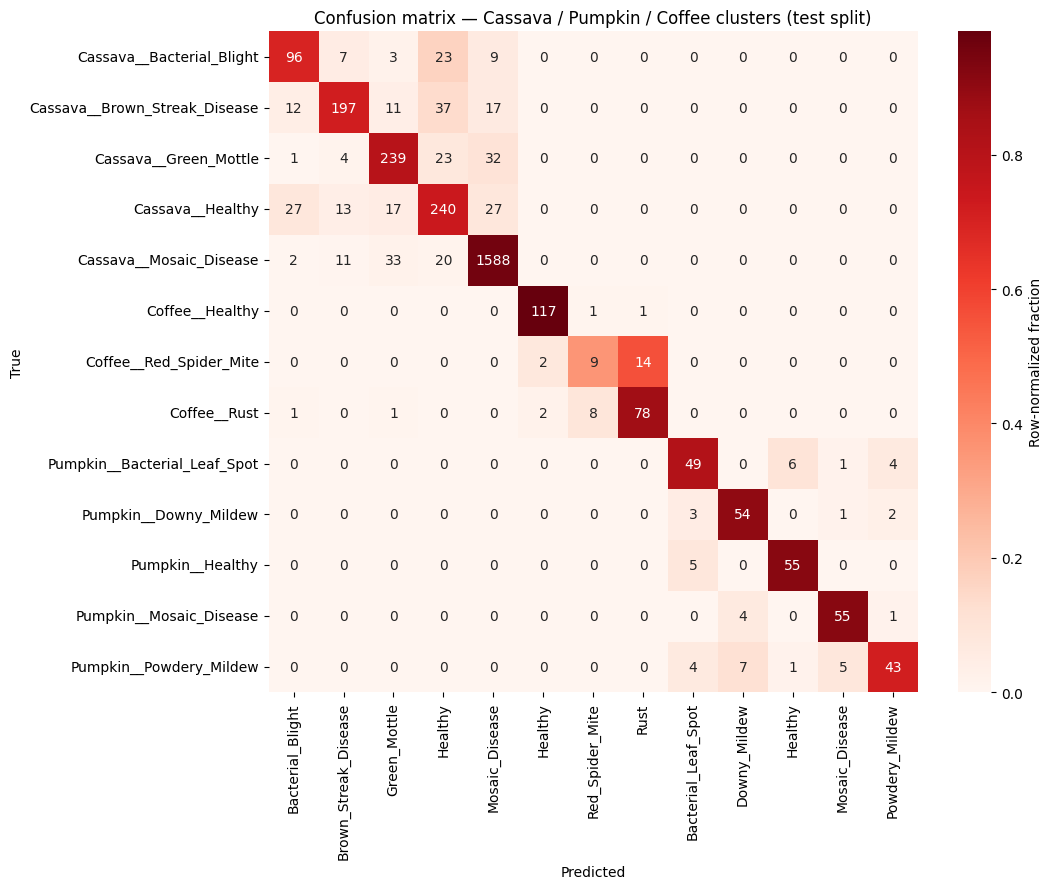


=== Where each flagged class's errors land ===

Cassava__Bacterial_Blight  (support=138, errors=42, F1 from earlier report applies here)
    → predicted as Cassava__Healthy                           23  (54.8% of its errors)
    → predicted as Cassava__Mosaic_Disease                     9  (21.4% of its errors)
    → predicted as Cassava__Brown_Streak_Disease               7  (16.7% of its errors)

Cassava__Brown_Streak_Disease  (support=274, errors=77, F1 from earlier report applies here)
    → predicted as Cassava__Healthy                           37  (48.1% of its errors)
    → predicted as Cassava__Mosaic_Disease                    17  (22.1% of its errors)
    → predicted as Cassava__Bacterial_Blight                  12  (15.6% of its errors)

Cassava__Green_Mottle  (support=299, errors=60, F1 from earlier report applies here)
    → predicted as Cassava__Mosaic_Disease                    32  (53.3% of its errors)
    → predicted as Cassava__Healthy                           23  

In [18]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

target_crops = ["Cassava", "Pumpkin", "Coffee"]
target_classes = sorted(c for c in class_to_idx if c.split("__")[0] in target_crops)
target_idx = [class_to_idx[c] for c in target_classes]

# Full 64x64 confusion matrix, then slice down to just the rows/cols we care about.
# Rows = true label, cols = predicted label (sklearn's default orientation).
cm_full = confusion_matrix(gt_labels, ensemble_preds, labels=range(n_classes))
cm_sub = cm_full[np.ix_(target_idx, target_idx)]

# Row-normalize so each row reads as "of the true examples of this class, what
# fraction got predicted as each class" — comparable across classes regardless
# of support size.
cm_sub_norm = cm_sub / cm_sub.sum(axis=1, keepdims=True)

short_labels = [c.split("__")[1] for c in target_classes]  # drop crop prefix, already grouped

plt.figure(figsize=(11, 9))
sns.heatmap(
    cm_sub_norm, annot=cm_sub, fmt="d", cmap="Reds",
    xticklabels=short_labels, yticklabels=target_classes,
    cbar_kws={"label": "Row-normalized fraction"},
)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion matrix — Cassava / Pumpkin / Coffee clusters (test split)")
plt.tight_layout()
plt.savefig("confusion_matrix_weak_clusters.png", dpi=150)
plt.show()

# Text summary: for each flagged class, where do its errors actually go?
print("\n=== Where each flagged class's errors land ===")
for i, cls in enumerate(target_classes):
    row = cm_sub[i]
    total_errs = row.sum() - row[i]
    if total_errs == 0:
        print(f"\n{cls}: no errors")
        continue
    print(f"\n{cls}  (support={row.sum()}, errors={total_errs}, F1 from earlier report applies here)")
    # top confused-into classes, excluding the correct diagonal entry
    order = np.argsort(row)[::-1]
    shown = 0
    for j in order:
        if j == i or row[j] == 0:
            continue
        pred_cls = target_classes[j]
        print(f"    → predicted as {pred_cls:<40} {row[j]:>4d}  ({row[j]/total_errs*100:.1f}% of its errors)")
        shown += 1
        if shown == 3:
            break

# Whole-model context: are these classes ALSO confused with something outside
# the three flagged crops? (row sums vs the sub-matrix row sums reveal this.)
print("\n=== Errors leaking outside the three flagged crops ===")
full_row_errors = cm_full[target_idx].sum(axis=1) - cm_full[target_idx, target_idx]
sub_row_errors = cm_sub.sum(axis=1) - np.diag(cm_sub)
outside_errors = full_row_errors - sub_row_errors
for cls, out_err, tot_err in zip(target_classes, outside_errors, full_row_errors):
    pct = (out_err / tot_err * 100) if tot_err > 0 else 0
    print(f"  {cls:<40} {out_err:>4d}/{tot_err:<4d} errors go outside the cluster ({pct:.1f}%)")

# 25: Prior-bias vs genuine-confusability tests (Cassava cluster)

In [19]:
cassava_classes = sorted(c for c in class_to_idx if c.startswith("Cassava"))
cassava_idx = [class_to_idx[c] for c in cassava_classes]

train_counts = dict(zip(df_counts["Class Name"], df_counts["Image Count"]))

# ---------------------------------------------------------------------------
# Test 1: observed vs. frequency-expected pull, within the Cassava family
# ---------------------------------------------------------------------------
print("=== Test 1: Observed pull vs. train-frequency-expected pull ===\n")
for y_cls in cassava_classes:
    y_idx = class_to_idx[y_cls]
    err_mask = (gt_labels == y_idx) & (ensemble_preds != y_idx)
    n_errors = err_mask.sum()
    if n_errors == 0:
        print(f"{y_cls}: no errors\n")
        continue

    other_cassava = [c for c in cassava_classes if c != y_cls]
    other_cassava_idx = [class_to_idx[c] for c in other_cassava]
    denom_train = sum(train_counts[c] for c in other_cassava)

    print(f"{y_cls}  (errors={n_errors})")
    for x_cls, x_idx in zip(other_cassava, other_cassava_idx):
        observed_pull = (ensemble_preds[err_mask] == x_idx).sum() / n_errors
        expected_pull = train_counts[x_cls] / denom_train
        ratio = observed_pull / expected_pull if expected_pull > 0 else np.nan
        flag = "  <- prior-driven" if 0.7 <= ratio <= 1.3 else ("  <- exceeds prior" if ratio > 1.3 else "")
        print(f"    -> {x_cls:<38} observed={observed_pull:.3f}  expected={expected_pull:.3f}  ratio={ratio:.2f}{flag}")
    print()

# ---------------------------------------------------------------------------
# Test 2: confidence margin (top1 - top2 softmax prob) on errors vs correct
# ---------------------------------------------------------------------------
print("=== Test 2: Softmax margin — errors vs. correct predictions ===\n")
sorted_probs = np.sort(ensemble_probs, axis=1)
margin = sorted_probs[:, -1] - sorted_probs[:, -2]  # top1 - top2

cassava_mask = np.isin(gt_labels, cassava_idx)
cassava_err_mask = cassava_mask & (ensemble_preds != gt_labels)
cassava_correct_mask = cassava_mask & (ensemble_preds == gt_labels)

print(f"Cassava correct predictions  (n={cassava_correct_mask.sum():4d}): "
      f"mean margin = {margin[cassava_correct_mask].mean():.4f}")
print(f"Cassava misclassifications   (n={cassava_err_mask.sum():4d}): "
      f"mean margin = {margin[cassava_err_mask].mean():.4f}")
print(f"  (whole-test-set error margin for reference: {margin[ensemble_preds != gt_labels].mean():.4f})")
print("\nInterpretation: low error-margin (close to 0) suggests low-confidence, "
      "prior-driven guessing. High error-margin (close to 1) suggests confident, "
      "genuine misreads.\n")

# ---------------------------------------------------------------------------
# Test 3: post-hoc inverse-frequency logit adjustment, no retraining
# ---------------------------------------------------------------------------
print("=== Test 3: Post-hoc logit adjustment (class-balanced reweighting) ===\n")

log_probs = np.log(np.clip(ensemble_probs, 1e-12, None))
train_freq = np.array([train_counts[idx_to_class[i]] for i in range(n_classes)])
log_prior = np.log(train_freq / train_freq.sum())

for tau in [0.5, 1.0, 1.5]:
    adjusted_log_probs = log_probs - tau * log_prior
    adjusted_preds = adjusted_log_probs.argmax(axis=1)

    adj_f1 = f1_score(gt_labels, adjusted_preds, average=None, labels=range(n_classes), zero_division=0)
    orig_f1 = f1_score(gt_labels, ensemble_preds, average=None, labels=range(n_classes), zero_division=0)

    print(f"--- tau={tau} ---")
    for cls in cassava_classes:
        idx = class_to_idx[cls]
        print(f"  {cls:<38} F1: {orig_f1[idx]:.4f} -> {adj_f1[idx]:.4f}  "
              f"({'+' if adj_f1[idx]>=orig_f1[idx] else ''}{adj_f1[idx]-orig_f1[idx]:.4f})")
    macro_before = orig_f1.mean()
    macro_after = adj_f1.mean()
    print(f"  Overall macro F1: {macro_before:.4f} -> {macro_after:.4f}  "
          f"({'+' if macro_after>=macro_before else ''}{macro_after-macro_before:.4f})\n")

=== Test 1: Observed pull vs. train-frequency-expected pull ===

Cassava__Bacterial_Blight  (errors=42)
    -> Cassava__Brown_Streak_Disease          observed=0.167  expected=0.108  ratio=1.55  <- exceeds prior
    -> Cassava__Green_Mottle                  observed=0.071  expected=0.117  ratio=0.61
    -> Cassava__Healthy                       observed=0.548  expected=0.127  ratio=4.30  <- exceeds prior
    -> Cassava__Mosaic_Disease                observed=0.214  expected=0.648  ratio=0.33

Cassava__Brown_Streak_Disease  (errors=78)
    -> Cassava__Bacterial_Blight              observed=0.154  expected=0.057  ratio=2.69  <- exceeds prior
    -> Cassava__Green_Mottle                  observed=0.141  expected=0.124  ratio=1.14  <- prior-driven
    -> Cassava__Healthy                       observed=0.474  expected=0.134  ratio=3.53  <- exceeds prior
    -> Cassava__Mosaic_Disease                observed=0.218  expected=0.685  ratio=0.32

Cassava__Green_Mottle  (errors=60)
    -> Cassava_

## 26 · Crop × Condition Heatmap (Publication Quality)

In [25]:
import plotly.express as px

# df_counts already exists in your notebook: Class ID / Class Name / Image Count
tax = df_counts.copy()
tax["Crop"] = tax["Class Name"].str.split("__").str[0].str.replace("_", " ")
tax["Class"] = tax["Class Name"].str.split("__").str[1].str.replace("_", " ")

fig = px.sunburst(
    tax,
    path=["Crop", "Class"],
    values="Image Count",
    title="CropQuery Dataset Taxonomy",
)
fig.update_layout(width=800, height=800)
fig.show()

In [38]:
import plotly.express as px

tax = df_counts.copy()
tax["Crop"] = tax["Class Name"].str.split("__").str[0].str.replace("_", " ")
tax["Class"] = tax["Class Name"].str.split("__").str[1].str.replace("_", " ")

def classify_status(class_name):
    if class_name == "Healthy":
        return "Healthy"
    if "Deficiency" in class_name:
        return "Nutrient Deficiency"
    if "Leaf_Miner" in class_name or "Mite" in class_name:
        return "Pest"
    return "Disease"

tax["Status"] = tax["Class Name"].str.split("__").str[1].apply(classify_status)

fig = px.sunburst(
    tax,
    path=["Crop", "Status", "Class"],
    values="Image Count",
    color="Status",
    color_discrete_map={
        "Healthy": "#2E7D32",              # Dark green
        "Disease": "#C62828",              # Dark red
        "Pest": "#F9A825",                 # Amber
        "Nutrient Deficiency": "#6A1B9A",  # Purple
    },
    title="<b>CropQuery Dataset Taxonomy</b><br><sup>132,955 Images • 18 Crops • 64 Classes • 4 Condition Categories</sup>",
)
fig.update_traces(
    insidetextorientation="radial",
    textfont=dict(
        family="Arial",
        size=16,
        color="white"
    ),
    marker=dict(line=dict(color="white", width=1))
)
fig.update_traces(root_color="white")
fig.update_layout(width=1000, height=1000, margin=dict(t=60, l=0, r=0, b=0))
fig.update_layout(
    font=dict(
        family="Arial",
        size=16,
        color="#222"
    ),
    title_font=dict(
        size=28,
        family="Arial",
        color="#1f2937"
    )
)
fig.show()

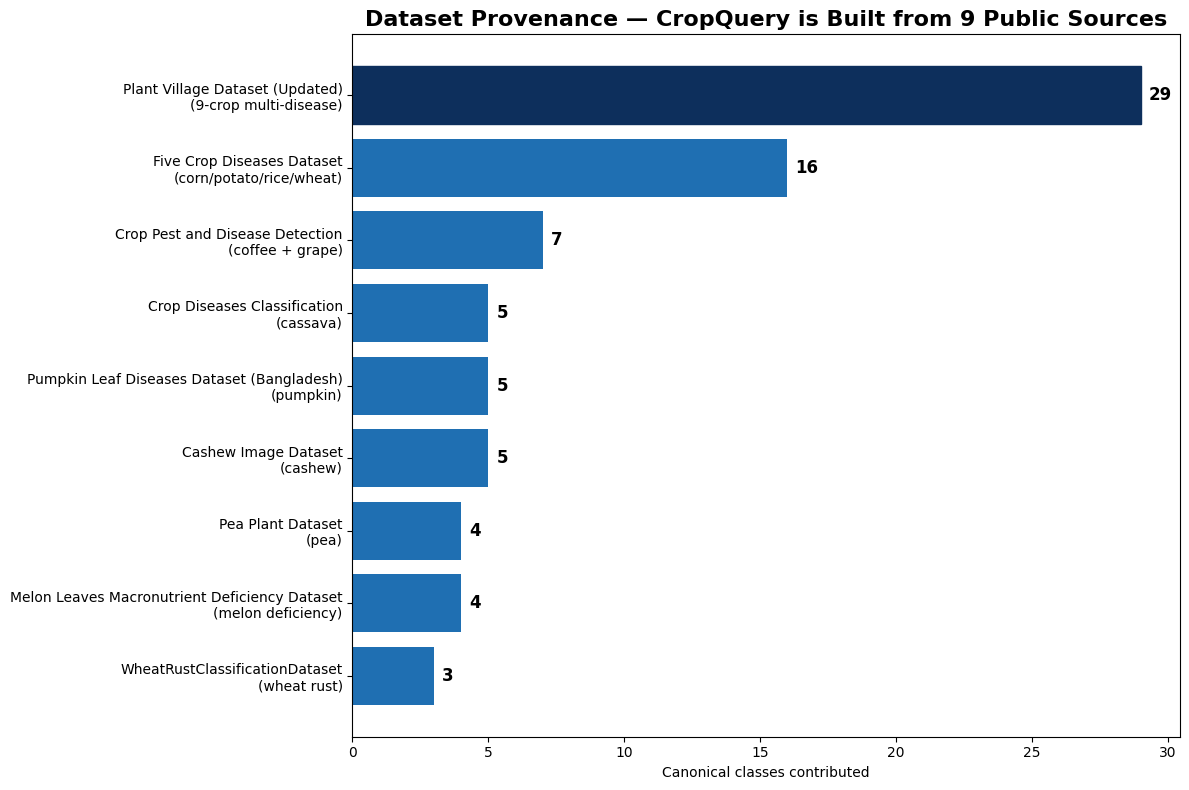

In [39]:
import matplotlib.pyplot as plt

# Kaggle username -> actual dataset title (looked up on kaggle.com)
dataset_titles = {
    "tushar5harma":    "Plant Village Dataset (Updated)",
    "shubham2703":     "Five Crop Diseases Dataset",
    "nirmalsankalana": "Crop Pest and Disease Detection",
    "mexwell":         "Crop Diseases Classification",
    "tahmidmir":       "Pumpkin Leaf Diseases Dataset (Bangladesh)",
    "ayushbpanchal":   "Cashew Image Dataset",
    "zunorain":        "Pea Plant Dataset",
    "binnassor89":     "Melon Leaves Macronutrient Deficiency Dataset",
    "yasaminborhani":  "WheatRustClassificationDataset",
}

crop_notes = {  # your existing per-source crop annotations
    "tushar5harma": "9-crop multi-disease",
    "shubham2703": "corn/potato/rice/wheat",
    "nirmalsankalana": "coffee + grape",
    "mexwell": "cassava",
    "tahmidmir": "pumpkin",
    "ayushbpanchal": "cashew",
    "zunorain": "pea",
    "binnassor89": "melon deficiency",
    "yasaminborhani": "wheat rust",
}

# counts dict — replace with your real per-source class counts (already computed earlier)
source_counts = {
    "tushar5harma": 29, "shubham2703": 16, "nirmalsankalana": 7, "mexwell": 5,
    "tahmidmir": 5, "ayushbpanchal": 5, "zunorain": 4, "binnassor89": 4,
    "yasaminborhani": 3,
}

sources_sorted = sorted(source_counts, key=source_counts.get, reverse=True)
labels = [f"{dataset_titles[s]}\n({crop_notes[s]})" for s in sources_sorted]
values = [source_counts[s] for s in sources_sorted]

fig, ax = plt.subplots(figsize=(12, 8))
bars = ax.barh(labels, values, color="#1f6fb2")
bars[0].set_color("#0d2f5c")  # highlight the largest source
ax.invert_yaxis()
for bar, v in zip(bars, values):
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2, str(v),
            va="center", fontsize=12, fontweight="bold")
ax.set_xlabel("Canonical classes contributed")
ax.set_title("Dataset Provenance — CropQuery is Built from 9 Public Sources",
              fontsize=16, fontweight="bold")
plt.tight_layout()
plt.savefig("dataset_provenance.png", dpi=150, bbox_inches="tight")
plt.show()